# 08. Cek Paham: Uji Model ASR pada FLEURS

Tiga model pengubah suara ke teks dibandingkan pada semua 687 rekaman bahasa Indonesia (split test) dari dataset Google FLEURS.

| Model | Jalan di | Peran |
|---|---|---|
| whisper-large-v3-turbo | API Groq | dipakai produksi |
| whisper-large-v3 | API Groq | pembanding |
| faster-whisper-small | CPU lokal | pembanding tanpa biaya API |

Metrik: WER (persen kata salah), CER (persen huruf salah), latensi (detik), dan RTF (latensi dibagi durasi audio).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import notebook_kit as kit
from src.evaluate_baseline import bootstrap_backend

pd.set_option("display.max_colwidth", 70)
import io

import pyarrow.parquet as pq
import requests
import soundfile as sf

KEYS = kit.use_keys(groq_env="GROQ_API_KEY_CEKPAHAM")
bootstrap_backend()
from src.asr import adapters, wer

SPLIT = "test"
N_CLIPS = None
SEED = 42
MODELS = ["groq-turbo", "groq-large-v3", "faster-whisper-small"]
GROQ_PAUSE_S = 3.5
TRANSIENT_ERRORS = {"stt_rate_limited", "stt_unavailable"}

DATA_DIR = ROOT / "data" / "asr_fleurs"
CACHE = ROOT / "data" / "cache" / "asr_fleurs.jsonl"
OUT = kit.results_dir("asr_fleurs")
DATA_DIR.mkdir(parents=True, exist_ok=True)

Kunci: groq ada, winston ada


## 1. Data

FLEURS berisi rekaman orang membacakan kalimat Wikipedia (lisensi CC-BY-4.0). Berkas diunduh sekali, lalu semua rekaman dipakai. Satu kalimat bisa dibacakan beberapa pembicara, dan tiap rekaman dihitung terpisah. Label gender di FLEURS id_id semuanya bernilai sama, jadi tidak dipakai untuk analisis.

In [2]:
PARQUET = DATA_DIR / f"fleurs_id_{SPLIT}.parquet"
URL = f"https://huggingface.co/api/datasets/google/fleurs/parquet/id_id/{SPLIT}/0.parquet"

if not PARQUET.exists():
    with requests.get(URL, stream=True, timeout=60) as response:
        response.raise_for_status()
        tmp = PARQUET.with_suffix(".part")
        with tmp.open("wb") as handle:
            for chunk in response.iter_content(chunk_size=1 << 20):
                handle.write(chunk)
        tmp.rename(PARQUET)
print(f"{PARQUET.name}: {PARQUET.stat().st_size / 1e6:.0f} MB")

meta = pq.read_table(PARQUET, columns=["id", "num_samples", "raw_transcription", "gender"]).to_pandas()
meta["row"] = meta.index
meta["gender"] = meta.gender.map({0: "laki-laki", 1: "perempuan", 2: "lainnya"})
meta["duration_s"] = meta.num_samples / 16_000

sample = (meta if N_CLIPS is None else meta.sample(N_CLIPS, random_state=SEED)).sort_values("row").reset_index(drop=True)
print(f"{len(sample)} rekaman dari {sample.id.nunique()} kalimat unik")
sample.duration_s.sum() / 60

fleurs_id_test.parquet: 543 MB


687 rekaman, 328 kalimat unik, diambil 100


gender
laki-laki    100
Name: count, dtype: int64

In [3]:
def export_audio(rows):
    wanted = set(rows.row)
    files, offset = {}, 0
    for batch in pq.ParquetFile(PARQUET).iter_batches(columns=["audio"], batch_size=64):
        for i, audio in enumerate(batch.column("audio").to_pylist()):
            if offset + i in wanted:
                path = DATA_DIR / f"clip_{offset + i:05d}.wav"
                if not path.exists():
                    data, rate = sf.read(io.BytesIO(audio["bytes"]))
                    sf.write(path, data, rate)
                files[offset + i] = path.name
        offset += batch.num_rows
    return rows.assign(file=rows.row.map(files))


sample = export_audio(sample)
assert sample.file.notna().all()
print(f"{len(sample)} klip, total {sample.duration_s.sum() / 60:.1f} menit audio")

100 klip, total 20.8 menit audio


## 2. Pra-pemrosesan

Teks rujukan dan hasil model dinormalisasi dengan fungsi yang sama: huruf kecil dan tanda baca dibuang, supaya beda tanda baca tidak dihitung salah.

In [4]:
examples = sample.head(3).assign(normal=lambda d: d.raw_transcription.map(lambda t: " ".join(wer.words(t))))
display(examples[["raw_transcription", "normal"]])
sample.duration_s.describe().round(1).to_frame("durasi (detik)").T

,raw_transcription,normal
0,"Semua nomina, di samping kata Sie untuk Anda, selalu dimulai denga...",semua nomina di samping kata sie untuk anda selalu dimulai dengan ...
1,Dia juga terlibat dalam pengukiran uang kertas untuk banyak negara...,dia juga terlibat dalam pengukiran uang kertas untuk banyak negara...
2,Mungkin juga akan menguntungkan bagi seseorang untuk membeli Wild ...,mungkin juga akan menguntungkan bagi seseorang untuk membeli wild ...


,count,mean,std,min,25%,50%,75%,max
durasi (detik),100.0,12.5,4.2,5.1,9.4,11.8,15.0,27.5


## 3. Pengujian

Setiap klip ditranskripsi ketiga model. Hasil disimpan di cache, jadi kalau kuota habis cukup jalankan ulang untuk melanjutkan.

In [5]:
cache = kit.load_jsonl(CACHE)


def build(name):
    if name.startswith("groq"):
        return (adapters.GroqAdapter(name), "") if KEYS["groq"] else (None, "kunci Groq kosong")
    adapter = adapters.FasterWhisperAdapter()
    try:
        adapter._model, load_s = kit.timed(adapter._load)
    except SystemExit as missing:
        return None, str(missing).splitlines()[0]
    print(f"faster-whisper-small dimuat dalam {load_s:.1f} detik")
    return adapter, ""


records, skipped = [], {}
for name in MODELS:
    adapter, reason = build(name)
    if adapter is None:
        skipped[name] = reason
        print(f"{name}: dilewati, {reason}")
        continue
    for clip in sample.itertuples():
        key = f"{name}:{SPLIT}:{clip.file}"
        entry = cache.get(key)
        if entry is None:
            try:
                result = adapter.transcribe(DATA_DIR / clip.file, "id", [])
            except adapters.QuotaExhausted:
                skipped[name] = "kuota habis, jalankan ulang untuk melanjutkan"
                print(f"{name}: {skipped[name]}")
                break
            entry = {"text": result.text, "seconds": round(result.seconds, 3), "error": result.error}
            if result.error not in TRANSIENT_ERRORS:
                cache[key] = entry
                kit.append_jsonl(CACHE, key, entry)
            if name.startswith("groq"):
                time.sleep(GROQ_PAUSE_S)
        records.append({"model": name, "file": clip.file, **entry})
    print(f"{name}: {sum(r['model'] == name for r in records)} klip")

runs = pd.DataFrame(records).merge(sample[["file", "gender", "duration_s", "raw_transcription"]], on="file")
runs["rtf"] = runs.seconds / runs.duration_s

groq-turbo: 100 klip


groq-large-v3: 100 klip


faster-whisper-small dimuat dalam 410.1 detik


faster-whisper-small: 100 klip


## 4. Hasil

WER dan CER dihitung per korpus: total kesalahan dibagi total kata rujukan. Interval 95% didapat dengan bootstrap.

In [6]:
def summarize(group):
    ok = group[group.error.fillna("") == ""]
    word = [wer.word_errors(r, h) for r, h in zip(ok.raw_transcription, ok.text)]
    char = [wer.char_errors(r, h) for r, h in zip(ok.raw_transcription, ok.text)]
    ci = wer.bootstrap_ci(word) or (np.nan, np.nan)
    return pd.Series({
        "klip": len(ok), "gagal": len(group) - len(ok),
        "WER": wer.corpus_rate(word), "WER bawah": ci[0], "WER atas": ci[1],
        "CER": wer.corpus_rate(char),
        "latensi median": ok.seconds.median(), "latensi p95": ok.seconds.quantile(0.95),
        "RTF median": ok.rtf.median(),
    })


results = runs.groupby("model").apply(summarize).reindex([m for m in MODELS if m in set(runs.model)])
results.round(3)

,klip,gagal,WER,WER bawah,WER atas,CER,latensi median,latensi p95,RTF median
model,,,,,,,,,
groq-turbo,100.0,0.0,0.066,0.052,0.083,0.024,0.960,1.555,0.075
groq-large-v3,100.0,0.0,0.061,0.049,0.077,0.020,1.048,1.734,0.082
faster-whisper-small,100.0,0.0,0.141,0.116,0.168,0.039,1.890,2.611,0.162


In [7]:
def wer_by(column):
    return runs.groupby(["model", column], observed=True).apply(
        lambda g: wer.corpus_rate([wer.word_errors(r, h) for r, h in zip(g.raw_transcription, g.text)])
    ).unstack().round(3)


runs["durasi"] = pd.cut(runs.duration_s, [0, 8, 12, 16, 60], labels=["<8 dtk", "8-12", "12-16", ">16"])
wer_by("durasi")

gender,laki-laki
model,
faster-whisper-small,0.141
groq-large-v3,0.061
groq-turbo,0.066


durasi,<8 dtk,8-12,12-16,>16
model,,,,
faster-whisper-small,0.254,0.135,0.166,0.087
groq-large-v3,0.079,0.059,0.070,0.047
groq-turbo,0.079,0.071,0.076,0.043


## 5. Perbandingan

Jawaban Cek Paham panjangnya 60 sampai 90 detik, lebih panjang dari klip FLEURS. Waktu tunggunya diperkirakan dari garis lurus latensi terhadap durasi audio.

In [8]:
def wait_for(seconds_of_audio, group):
    slope, intercept = np.polyfit(group.duration_s, group.seconds, 1)
    return intercept + slope * seconds_of_audio


comparison = results[["WER", "CER", "latensi median", "RTF median"]].copy()
for audio_s in (60, 90):
    comparison[f"tunggu {audio_s} dtk audio"] = [wait_for(audio_s, runs[runs.model == m]) for m in comparison.index]
comparison.round(3)

,WER,CER,latensi median,RTF median,tunggu 60 dtk audio,tunggu 90 dtk audio
model,,,,,,
groq-turbo,0.066,0.024,0.960,0.075,3.122,4.482
groq-large-v3,0.061,0.020,1.048,0.082,3.780,5.426
faster-whisper-small,0.141,0.039,1.890,0.162,6.270,8.980


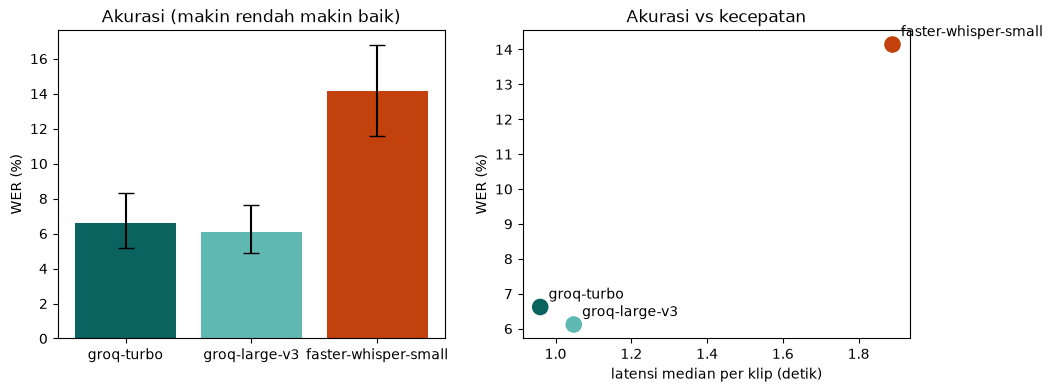

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#0B635F", "#5FB8B2", "#C2410C"][: len(results)]
left.bar(results.index, results.WER * 100, color=colors,
         yerr=[(results.WER - results["WER bawah"]) * 100, (results["WER atas"] - results.WER) * 100], capsize=6)
left.set_ylabel("WER (%)")
left.set_title("Akurasi (makin rendah makin baik)")
right.scatter(results["latensi median"], results.WER * 100, s=120, color=colors)
for name, row in results.iterrows():
    right.annotate(name, (row["latensi median"], row.WER * 100), xytext=(6, 6), textcoords="offset points")
right.set_xlabel("latensi median per klip (detik)")
right.set_ylabel("WER (%)")
right.set_title("Akurasi vs kecepatan")
kit.save_figure(fig, "asr_fleurs_perbandingan.png")
plt.show()

In [10]:
def worst(model, n=5):
    part = runs[runs.model == model].copy()
    part["WER klip"] = [e / max(n_ref, 1) for e, n_ref in (wer.word_errors(r, h) for r, h in zip(part.raw_transcription, part.text))]
    return part.nlargest(n, "WER klip")[["file", "WER klip", "raw_transcription", "text"]]


for name in results.index:
    print(name)
    display(worst(name))

groq-turbo


,file,WER klip,raw_transcription,text
52,clip_00327.wav,0.500000,"Lakkha Singh juga menampilkan chhappan bhog bhajan. Penyanyi, Raju...","Lakha Singh juga menampilkan capan bok bajan, menyanyi Raju Kandel..."
84,clip_00622.wav,0.300000,Kepulauan ini terletak 120 km dari utara Semenanjung. Pulau terbes...,kepulauan ini terletak seratus dua puluh kilometer dari utara seme...
68,clip_00477.wav,0.285714,Aerosmith meniadakan konser tur mereka yang tersisa.,Aerosmith menyadakan konsep tur mereka yang tersisa
22,clip_00135.wav,0.277778,"Jika Anda tidak terbiasa mengemudi di jalan pedesaan, waspadalah: ...","Jika Anda tidak terbiasa mengembudu di jalan perasaan, waspadalah...."
63,clip_00409.wav,0.272727,Kantor gubernur mengatakan sembilan belas orang yang terluka merup...,Kantor gubernur menyatakan 19 orang yang terluka merupakan aparat ...


groq-large-v3


,file,WER klip,raw_transcription,text
152,clip_00327.wav,0.500000,"Lakkha Singh juga menampilkan chhappan bhog bhajan. Penyanyi, Raju...","Lakha Singh juga menampilkan capan bok bhajan, menyanyi rajukan di..."
168,clip_00477.wav,0.428571,Aerosmith meniadakan konser tur mereka yang tersisa.,Aerosmith menyadarkan konsertur mereka yang tersisa
163,clip_00409.wav,0.272727,Kantor gubernur mengatakan sembilan belas orang yang terluka merup...,Kantor gubernur menyatakan 19 orang yang terluka merupakan aparat ...
196,clip_00668.wav,0.250000,"Selama Perang Revolusi, tiga belas negara bagian pertama-tama memb...","Selama perang revolusi, 13 negara bagian pertama-tama membentuk se..."
140,clip_00256.wav,0.222222,Badai kesepuluh dari musim Badai Atlantik yang diberi nama Badai S...,Badai ke-10 dari musim badai Atlantik yang diberi nama badai subtr...


faster-whisper-small


,file,WER klip,raw_transcription,text
252,clip_00327.wav,0.666667,"Lakkha Singh juga menampilkan chhappan bhog bhajan. Penyanyi, Raju...","Lakh Hasing juga menampilkan capan bok bajan, menyanyi rajukan del..."
268,clip_00477.wav,0.571429,Aerosmith meniadakan konser tur mereka yang tersisa.,AeroSmith menyadakan konsertur Maraita yang tersisa.
266,clip_00451.wav,0.461538,Penelitian abad ke-20 menunjukkan bahwa ada dua variasi genetik: t...,Peneliti yang abad kedua puluh menunjukkan bahwa ada dua variasi k...
263,clip_00409.wav,0.454545,Kantor gubernur mengatakan sembilan belas orang yang terluka merup...,kantor gubunir menyatakan 19 orang yang terluka merupakan aparat k...
231,clip_00220.wav,0.444444,Anggaplah rute ski sebagai rute pendakian yang tidak asing.,Angka pelah rute seki sebagai rute pendagian yang tidak asing.


## 6. Kesimpulan

FLEURS berisi ucapan yang dibacakan dengan jelas. Jawaban Cek Paham spontan dan penuh istilah teknis, jadi WER sebenarnya kemungkinan lebih tinggi dari angka di sini.

In [11]:
best = results.WER.idxmin()
fastest = results["latensi median"].idxmin()
results.round(4).to_csv(OUT / "ringkasan_model.csv")
runs.drop(columns=["durasi"]).to_csv(OUT / "per_klip.csv", index=False)

kit.write_summary(OUT / "ringkasan.md", f"ASR Cek Paham pada FLEURS id_id ({SPLIT}, {len(sample)} klip)", {
    "Hasil": kit.md_table(comparison.round(3)),
    "Dilewati": "\n".join(f"- {k}: {v}" for k, v in skipped.items()) or "- tidak ada",
    "Temuan": f"- WER terendah: {best} ({results.WER[best]:.1%}).\n"
              f"- Tercepat: {fastest} (median {results['latensi median'][fastest]:.2f} detik per klip).\n"
              "- Model produksi saat ini adalah groq-turbo.",
    "Batasan": "Ucapan dibacakan dan bersih, jadi WER jawaban spontan kemungkinan lebih tinggi. "
               "Waktu tunggu 60-90 detik adalah perkiraan.",
})
print((OUT / "ringkasan.md").read_text())

# ASR Cek Paham pada FLEURS id_id (test, 100 klip)

## Hasil

| model | WER | CER | latensi median | RTF median | tunggu 60 dtk audio | tunggu 90 dtk audio |
|---|---|---|---|---|---|---|
| groq-turbo | 0.066 | 0.024 | 0.96 | 0.075 | 3.122 | 4.482 |
| groq-large-v3 | 0.061 | 0.02 | 1.048 | 0.082 | 3.78 | 5.426 |
| faster-whisper-small | 0.141 | 0.039 | 1.89 | 0.162 | 6.27 | 8.98 |

## Dilewati

- tidak ada

## Temuan

- WER terendah: groq-large-v3 (6.1%).
- Tercepat: groq-turbo (median 0.96 detik per klip).
- Model produksi saat ini adalah groq-turbo.

## Batasan

Ucapan dibacakan dan bersih, jadi WER jawaban spontan kemungkinan lebih tinggi. Waktu tunggu 60-90 detik adalah perkiraan.

